In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import global_mean_pool, NNConv
from sklearn.model_selection import train_test_split
from torch_geometric.loader import DataLoader


from build_graphs import fast_graphy

/home/amutua/inverse/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The data

In [2]:
# load full graphs
# full_train_graphs = torch.load(f"graphs/full_train_graphs.pt", weights_only=False)
# full_val_graphs = torch.load(f"graphs/full_val_graphs.pt", weights_only=False)
# full_test_graphs = torch.load(f"graphs/full_test_graphs.pt", weights_only=False)

# sample
comb_df = pd.read_csv("combined/combined_data.csv")
comb_df = comb_df[comb_df['defect_sites'] != 1]
_, sample_df = train_test_split(comb_df, test_size=0.25, stratify=comb_df['strata'], random_state=42)

sample_train, sample_test = train_test_split(sample_df, test_size=0.2, stratify=sample_df['strata'], random_state=42)
sample_val, sample_test = train_test_split(sample_test, test_size=0.5, stratify=sample_test['strata'], random_state=42)

sample_train_graphs = fast_graphy(sample_train)
sample_val_graphs = fast_graphy(sample_val)
sample_test_graphs = fast_graphy(sample_test)


Working on low_WSe2...


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 48 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 47 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 46 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 45 fractional coordi

Working on low_MoS2...
Working on high_InSe...
Working on high_MoS2...


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 43 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 41 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 42 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 32 fractional coordi

Working on high_BN...


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 30 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 28 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 29 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 27 fractional coordi

Working on high_GaSe...
Working on high_P...


/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 24 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 20 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 23 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  struct = parser.parse_structures(primitive=primitive)[0]
/home/amutua/inverse/lib/python3.10/site-packages/pymatgen/core/structure.py:3109: UserWarning: Issues encountered while parsing CIF: 22 fractional coordi

Working on high_WSe2...
Working on low_WSe2...
Working on low_MoS2...
Working on high_P...
Working on high_GaSe...
Working on high_MoS2...
Working on high_BN...
Working on high_InSe...
Working on high_WSe2...
Working on high_MoS2...
Working on low_WSe2...
Working on low_MoS2...
Working on high_GaSe...
Working on high_BN...
Working on high_InSe...
Working on high_WSe2...
Working on high_P...


In [3]:
# full_train_graphs[0]
sample_train_graphs[0]

Data(x=[3, 8], edge_index=[2, 9], edge_attr=[9, 3], y=[1], the_ids=[1, 2], the_ratios=[1, 2])

In [4]:
# Create data loaders
train_loader = DataLoader(sample_train_graphs, batch_size=1, shuffle=True)
val_loader = DataLoader(sample_val_graphs, batch_size=1, shuffle=False)
test_loader = DataLoader(sample_test_graphs, batch_size=1, shuffle=False)

## The model

In [5]:
class GNNModel(nn.Module):
    def __init__(self, node_dim=8, edge_dim=3, hidden_dim=32, embed_dim=64):
        super().__init__()
        # Edge NN maps edge_attr to weight matrix
        self.edge_nn = nn.Sequential(
            nn.Linear(edge_dim, 32),
            nn.ReLU(),
            nn.Linear(32, node_dim * hidden_dim)
        )

        self.element_embedding = nn.Embedding(118, embed_dim)

        self.conv1 = NNConv(node_dim, hidden_dim, self.edge_nn, aggr='mean')

        self.fc0 = nn.Linear(hidden_dim + embed_dim, 64)
        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 1)

    def get_u(self, the_ids, the_ratios):
        emb = self.element_embedding(the_ids)
        weighted_emb = emb * the_ratios.unsqueeze(1)
        return weighted_emb.sum(dim=0)

    def forward(self,data):
        x = F.relu(self.conv1(data.x, data.edge_index, data.edge_attr))
        x = global_mean_pool(x, data.batch)
        idss = data.the_ids.squeeze(0)
        ratioss = data.the_ratios.squeeze(0)
        global_attr = self.get_u(idss.to(self.element_embedding.weight.device),
                                 ratioss.to(self.element_embedding.weight.device)
                                 ).expand(x.size(0), -1)

        x = torch.cat([x, global_attr], dim=1)
        x = F.relu(self.fc0(x))
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

class LogCoshLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, input, target):
        ey_t = input-target
        return torch.mean(torch.log(torch.cosh(ey_t + 1e-12)))

# Instantiate model, optimizer, loss
# run the model in the gpu if the device has one
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instance of the model
GNN_model = GNNModel().to(device)

# optimizer
optimizer = torch.optim.Adam(GNN_model.parameters(), lr=0.001)

# Loss function
# loss_fn = nn.MSELoss()
loss_fn = LogCoshLoss()

In [6]:
def train(model, train_loader):
    model.train()
    total_loss = 0
    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()

        out = model(data)
        loss = loss_fn(out, data.y)

        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(train_loader.dataset)

def evaluate(model, loader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for data in loader:
            data = data.to(device)

            out = model(data)
            loss = loss_fn(out, data.y)

            total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)

def predict(model, loader, actuals=False):
    model.eval()
    if actuals:
        predictions = []
        actual = []
        with torch.no_grad():
            for data in loader:
                data = data.to(device)

                out = model(data)
                predictions.append(out.cpu().numpy())
                actual.append(data.y.cpu().numpy())

        predictions = np.array(predictions).flatten()
        actual = np.array(actual).flatten()
        return predictions, actual
    else:
        predictions = []
        with torch.no_grad():
            for data in loader:
                data = data.to(device)

                out = model(data)
                predictions.append(out.cpu().numpy())

        return np.array(predictions).flatten()

In [7]:
# Train model
the_model = GNN_model
train_losses = []
val_losses = []
for epoch in range(1, 21):
    train_loss = train(the_model, train_loader)
    val_loss = evaluate(the_model,val_loader)
    print(f'Epoch {epoch:03d}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')
    train_losses.append(train_loss)
    val_losses.append(val_loss)

# Test model
test_loss = evaluate(the_model, test_loader)
print(f'Test Loss: {test_loss:.4f}')

Epoch 001, Train Loss: 0.0541, Val Loss: 0.0204
Epoch 002, Train Loss: 0.0148, Val Loss: 0.0142
Epoch 003, Train Loss: 0.0128, Val Loss: 0.0093
Epoch 004, Train Loss: 0.0106, Val Loss: 0.0101
Epoch 005, Train Loss: 0.0096, Val Loss: 0.0100
Epoch 006, Train Loss: 0.0093, Val Loss: 0.0088
Epoch 007, Train Loss: 0.0088, Val Loss: 0.0098
Epoch 008, Train Loss: 0.0085, Val Loss: 0.0088
Epoch 009, Train Loss: 0.0083, Val Loss: 0.0087
Epoch 010, Train Loss: 0.0084, Val Loss: 0.0087
Epoch 011, Train Loss: 0.0078, Val Loss: 0.0087
Epoch 012, Train Loss: 0.0080, Val Loss: 0.0096
Epoch 013, Train Loss: 0.0079, Val Loss: 0.0093
Epoch 014, Train Loss: 0.0077, Val Loss: 0.0096
Epoch 015, Train Loss: 0.0076, Val Loss: 0.0082
Epoch 016, Train Loss: 0.0073, Val Loss: 0.0082
Epoch 017, Train Loss: 0.0072, Val Loss: 0.0084
Epoch 018, Train Loss: 0.0075, Val Loss: 0.0093
Epoch 019, Train Loss: 0.0070, Val Loss: 0.0091
Epoch 020, Train Loss: 0.0071, Val Loss: 0.0086
Test Loss: 0.0061


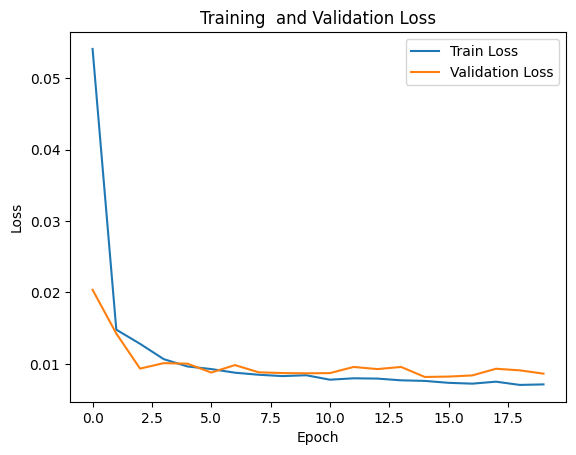

In [8]:
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training  and Validation Loss')
plt.legend()
plt.show()

In [9]:
# Predict values

predicted_values, actual_values = predict(the_model, test_loader, actuals=True)

## Visualize predicted value and actual value

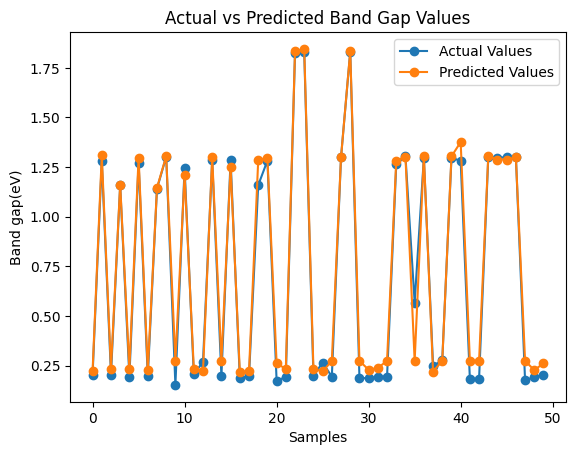

In [10]:
plt.plot(actual_values[100:150], label='Actual Values', marker='o')
plt.plot(predicted_values[100:150], label='Predicted Values', marker='o')
plt.xlabel('Samples')
plt.ylabel('Band gap(eV)')
plt.title('Actual vs Predicted Band Gap Values')
plt.legend()
plt.show()

In [11]:
for i in range(10):
    print(f"Actual: {actual_values[i]}, Predict: {predicted_values[i]}")

Actual: 0.3352000117301941, Predict: 0.38798028230667114
Actual: 0.38749998807907104, Predict: 0.38923338055610657
Actual: 0.04769999906420708, Predict: 0.18458139896392822
Actual: 0.05220000073313713, Predict: 0.1542166769504547
Actual: 0.07970000058412552, Predict: 0.10354375839233398
Actual: 0.07559999823570251, Predict: 0.10907362401485443
Actual: 0.18799999356269836, Predict: 0.21232599020004272
Actual: 0.11919999867677689, Predict: 0.13958600163459778
Actual: 0.06430000066757202, Predict: 0.133495032787323
Actual: 0.3467999994754791, Predict: 0.241962268948555


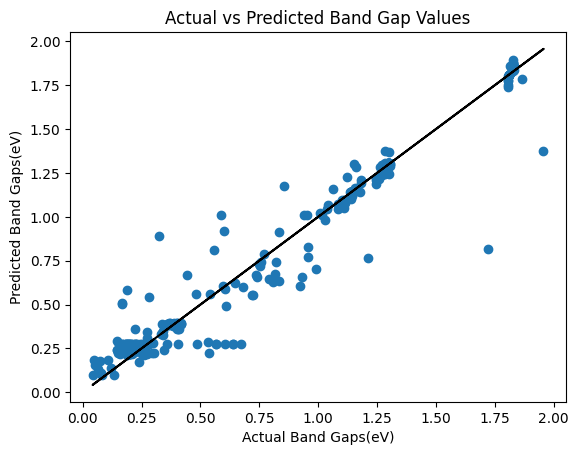

In [12]:
# Produce a graph
plt.scatter(actual_values, predicted_values )
plt.plot(actual_values, actual_values, c="black")
plt.xlabel('Actual Band Gaps(eV)')
plt.ylabel('Predicted Band Gaps(eV)')
plt.title('Actual vs Predicted Band Gap Values')
plt.show()

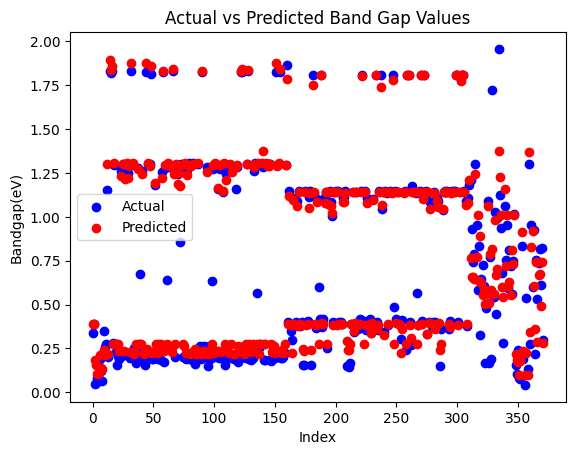

In [13]:
indices = range(len(actual_values))

plt.scatter(indices, actual_values, color='blue', label='Actual')
plt.scatter(indices, predicted_values, color='red', label='Predicted')
plt.xlabel('Index')
plt.ylabel('Bandgap(eV)')
plt.title('Actual vs Predicted Band Gap Values')
plt.legend()
plt.show()

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(actual_values, predicted_values)
mse = mean_squared_error(actual_values, predicted_values)
r2 = r2_score(actual_values, predicted_values)

print(f'Mean Absolute Error: {mae:.4f}')
print(f'Mean Squared Error: {mse:.4f}')
print(f'R-squared: {r2:.4f}')

Mean Absolute Error: 0.0571
Mean Squared Error: 0.0127
R-squared: 0.9557


In [15]:
# Save model
path_file = "models/GNN_Model.pth"
torch.save(the_model.state_dict(), path_file)